In [51]:
import pandas as pd
import re
import json
import ast
from os import fdopen, remove
from tempfile import mkstemp
from shutil import move, copymode
from pprint import pprint 
from io import StringIO
import os
import string
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

sents_years_path = "/Users/sofiaromero/Desktop/Leipzig_sentences_years.csv"


def flatten(xss):
    return [x for xs in xss for x in xs]

### Daten veranschaulichen:
- Häufigkeit der KI Terme
- Häufigste Wörter
- TF-IDF Wörter Veranschaulichen
- length of sentences / number of clauses
- number / type of verbs
- number / type of adjektives

In [52]:
plots_dir = "plots/"
try:
    os.mkdir(plots_dir)
    print(f"Directory '{plots_dir}' created successfully.")
except FileExistsError:
    print(f"Directory '{plots_dir}' already exists.")

Directory 'plots/' already exists.


In [53]:
docs_ki = pd.read_json(StringIO(open('generated_data/KI_sentences_tfidf.json').read()), orient="index")

ki_docs = docs_ki[docs_ki['sentences'].isna() == False].reset_index()
non_ki_docs = docs_ki[docs_ki['sentences'].isna() == True].reset_index()

print(f"Number of KI docs: {len(ki_docs)}")
print(f"Number of other docs: {len(non_ki_docs)}")
non_ki_docs.head()

Number of KI docs: 0
Number of other docs: 152225


,index,sentences,top_words
0,6036703.txt,NaN,"['unterstützen', 'zwangshaft söder', 'genüssli..."
1,0224025.txt,NaN,"['zivilisten dramatischen', 'nkunda erschütter..."
2,5903496.txt,NaN,"['kommunist laufe', 'radikalisieren', 'kommuni..."
3,1184664.txt,NaN,"['andré', 'andré kunz', 'kunz', 'ishikawa prof..."
4,806049.txt,NaN,"['patienten fördern', 'patienten', 'gesundheit..."


In [54]:
docs_ai = pd.read_json(StringIO(open('generated_data/AI_sentences_tfidf.json').read()), orient="index")

ai_docs = docs_ai[docs_ai['sentences'].isna() == False].reset_index()
non_ai_docs = docs_ai[docs_ai['sentences'].isna() == True].reset_index()

print(f"Number of AI docs: {len(ai_docs)}")
print(f"Number of other docs: {len(non_ai_docs)}")
docs_ai.head()

Number of AI docs: 0
Number of other docs: 574


,sentences,top_words
5315432.txt,NaN,"['scooter 25', 'scooter', 'pushes scooter', 'p..."
5124643.txt,NaN,"['unarmed civilians', 'government forces', 'ba..."
5094180.txt,NaN,"['weiwei does', 'weiwei', 'shortcoming', 'nomi..."
851887.txt,NaN,"['philipp palm', 'philipp', 'palm crisis', 'pa..."
5455271.txt,NaN,"['world 2000', 'world', 'ki', '2000 ki', '2000']"


In [55]:
# filtered Ki sentences with regex
docs_sents = pd.read_csv(StringIO(open('generated_data/KI_sentences_translated.csv').read()))
docs_full = pd.read_csv(StringIO(open('generated_data/KI_sentences_full_translated.csv').read()))

with open("generated_data/Leipzig_KI_sentences_all.json", "r") as f:
    docs_leipzig = json.load(f)

print(f"Number of docs_full: {len(docs_full)}")
print(f"Number of docs_sents: {len(docs_sents)}")
docs_sents.head()

Number of docs_full: 150
Number of docs_sents: 1490


,id,text,translation
0,5315432.txt,der elek­tro­mo­tor pusht den rol­ler auf bis ...,the electric motor pushes the scooter up to 25...
1,5124643.txt,ungeneralsekretär ban ki moon bezeichnete die ...,secretary-general ban ki moon calls the killin...
2,5094180.txt,gegen dieses manko hilft auch die nominierung ...,"even the nomination of the chinese ""architect""..."
3,851887.txt,taz herr palm man liest von gewalt an ihrer sc...,taz mr palm you read about violence at your sc...
4,851887.txt,philipp palm es ist nicht so dass wir in einer...,philipp palm it is not that we are in a seriou...


In [56]:
stopwords = open("config_files/spacy_stopwords.txt").read().replace("{", '[').replace("}",']')
stopwords = ast.literal_eval(stopwords)

# this one is not needed if working on Sentence_spacy
def remove_punctuation(corpus):
    cleaned_corpus = corpus.translate(str.maketrans('', '', string.punctuation))
    return(cleaned_corpus)

# remove stop words from text
def remove_stop_words_from_text(cleaned_corpus):
    out = [word for word in cleaned_corpus if not word in stopwords]
    out_text = ' '.join(out)
    return out_text  # , out

In [57]:
def sents_per_year(df):
    try:
        with open('corpus_texts/taz24_metadata.json', 'r', encoding='utf-8') as f:
            meta = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError("metadata file not found")
    
    df_res = pd.DataFrame(df).copy()
    year_col = []
    # Map ids in dataframe to years using metadata; fall back to extracting year from id if present
    for id_df in df["id"]:
        id_str = re.sub(r'\.\w+$', '', id_df).replace('_full', '')  # remove file extension and underscores
        if id_str not in meta:
            print(f"Warning: id {id_df, id_str} not found in metadata")
        else:
            meta_year = meta[id_str].get("published_on")
            year = re.match(r'(\d{4})', meta_year).group(1)
            if year is None:
                print(f"Warning: published_on missing for id {id_df, id_str} in metadata")
                year_col.append("0000")
            else:
                year_col.append(year)
    df_res['year'] = year_col
    df_res.to_csv(sents_years_path, index=False)
    
    return df_res


def get_POS(token_list):
    return [token.pos_ for token in token_list]

# helper to obtain tokens from an element
def tokens_from_item(item, nlp):
    # spaCy Token lists / Docs / Spans 
    if hasattr(item, "pos_") or (hasattr(item, "__iter__") and not isinstance(item, str) and len(item) and hasattr(item[0], "pos_")):
        # item is a Token, Doc, Span, or list of Tokens
        return list(item)
    return list(nlp(str(item)))

# Count top words by POS tag (supports token lists, spaCy Docs/Spans, or raw text)
def get_top_POS(df_col, pos, k):
    # detect whether we need to load a model (when any element is a string)
    try:
        # df_col can be a pandas Series
        iterable = df_col
        if hasattr(df_col, "dropna"):
            iterable = df_col.dropna().values
    except Exception:
        iterable = df_col

    counts = Counter()
    for item in iterable:
        tokens = _tokens_from_item(item, nlp)
        for token in tokens:
            # ensure token has pos_ and is alphabetic
            if getattr(token, "pos_", None) == pos and getattr(token, "is_alpha", False):
                lemma = getattr(token, "lemma_", token.text).lower()
                counts[lemma] += 1

    top_k = pd.Series(dict(counts.most_common(k)))
    print(f"\n{k} most frequent {pos}:\n", top_k)
    return top_k

In [58]:
# Häufigste Wörter insgesamt
def top_words(df_col, k):
    top_k = df_col.str.split().apply(lambda x: pd.Series(remove_stop_words_from_text(x))).stack().value_counts().head(k)
    print(f"\n{k} most frequent words:\n", top_k)
    return top_k

# Häufigste Wörter pro jahr 
def top_words_per_year(df, k): 
    top_k_year = df.groupby('year')['text'].apply(lambda x: x.str.split().apply(lambda y: pd.Series(y)).stack().value_counts().head(k))
    print(f"\n{k} most frequent words per year:\n", top_k_year)
    return top_k_year

#### TFIDF of KI_sentences filtered with regex

In [59]:
# compare KI_sentences and KI_sentences_full ids
ids_full = [x.replace("_full", "") for x in docs_full["id"].tolist()]
all_ids = docs_sents["id"].tolist() + ids_full
set_all_ids = set(all_ids)
set_all_og_ids = set(docs_sents["id"].tolist() + docs_full["id"].tolist())
non_repeated_ids = [x for x in set_all_ids if x not in ids_full] + [x for x in ids_full if x not in set_all_ids]
print(f"Number of ids: {len(all_ids)}, len unique ids: {len(set_all_ids)}, len non-repeated ids: {len(non_repeated_ids)}")
print("Non-repeated ids:", str(non_repeated_ids))
print("all original ids:", str(set_all_og_ids))

# separate tfidf of ai-sentences and others


# combine

# calc tfidf on result

# visualize, ideally against other tfidf(s)


Number of ids: 1640, len unique ids: 578, len non-repeated ids: 428
Non-repeated ids: ['5902471.txt', '5485956.txt', '807776.txt', '1736262.txt', '590719.txt', '5148317.txt', '0409858.txt', '3197013.txt', '1917552.txt', '1855418.txt', '5321736.txt', '5455721.txt', '0320467.txt', '485521.txt', '477818.txt', '5167431.txt', '0242523.txt', '1609184.txt', '1249570.txt', '0314136.txt', '5320928.txt', '5488023.txt', '480269.txt', '5827864.txt', '493149.txt', '5906753.txt', '5124404.txt', '5777644.txt', '5147373.txt', '0313735.txt', '5193478.txt', '5447226.txt', '1737898.txt', '5094450.txt', '5772902.txt', '5905596.txt', '5727648.txt', '5069465.txt', '5725090.txt', '0243231.txt', '650886.txt', '1109642.txt', '1183035.txt', '5148089.txt', '5490124.txt', '791425.txt', '5023336.txt', '1459696.txt', '5320885.txt', '5455271.txt', '5319692.txt', '5050389.txt', '0403353.txt', '1606837.txt', '5123913.txt', '5905406.txt', '5829220.txt', '731416.txt', '5572318.txt', '5722229.txt', '1305612.txt', '479671

#### KI_sentence stats

In [60]:
# number of sentences per year — compute and plot
sents_by_year = sents_per_year(docs_sents)
sents_by_year.head()

,id,text,translation,year
0,5315432.txt,der elek­tro­mo­tor pusht den rol­ler auf bis ...,the electric motor pushes the scooter up to 25...,2016
1,5124643.txt,ungeneralsekretär ban ki moon bezeichnete die ...,secretary-general ban ki moon calls the killin...,2011
2,5094180.txt,gegen dieses manko hilft auch die nominierung ...,"even the nomination of the chinese ""architect""...",2012
3,851887.txt,taz herr palm man liest von gewalt an ihrer sc...,taz mr palm you read about violence at your sc...,2008
4,851887.txt,philipp palm es ist nicht so dass wir in einer...,philipp palm it is not that we are in a seriou...,2008


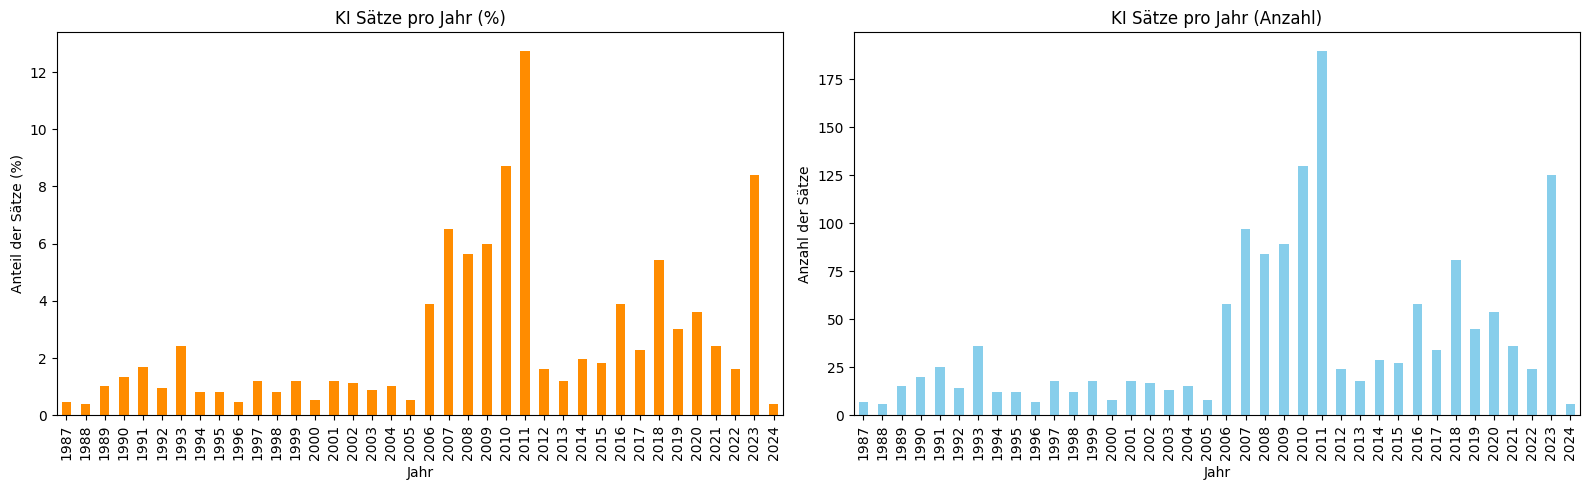

<Figure size 640x480 with 0 Axes>

In [ ]:
# exclude unknown years ('0000') and aggregate counts
sents_years = pd.Series(sents_by_year['year'])
sents_years = sents_years[sents_years != '0000']
sents_years = sents_years.value_counts().sort_index()
# calc percentaes
sents_by_year_percent = (sents_years / sents_years.sum()) * 100
sents_by_year_percent = sents_by_year_percent.round(2)
# save percentages
pd.DataFrame({'year': sents_years, 'percentage': sents_by_year_percent}).to_csv(sents_years_path,index= False)

#####

# Leipzig per-year plot: counts (bars) and percentage (line)
# Recompute year lists to be robust if earlier cells weren't run in order
years = sents_years#sorted(set(list(year_counts.keys()) + list(year_total_counts.keys())))
counts = [year_counts.get(y, 0) for y in years]
totals = [year_total_counts.get(y, 0) for y in years]
percentages = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts, totals)]

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(years, counts, color='skyblue', edgecolor='black', label='Anzahl anthropomorpher Sätze')
ax1.set_xlabel('Jahr', fontsize=18)
ax1.set_ylabel('Anzahl anthropomorpher Sätze', color='skyblue', fontsize=18)
ax1.tick_params(axis='y', labelcolor='skyblue', labelsize=15)
ax1.set_xticklabels(years, rotation=45, size=15)

ax2 = ax1.twinx()
ax2.plot(years, percentages, color='darkorange', marker='o', linewidth=2, label='Prozentsatz (%)')
ax2.set_ylabel('Prozentsatz (%)', color='darkorange', fontsize=18)
ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=15)

fig.suptitle('Leipzig: Anthropomorphie pro Jahr — Anzahl und Prozentsatz', fontsize=18)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
# combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines + lines2, labels + labels2, loc='upper left')
plt.show()
# Save figure
plt.savefig(plots_dir + 'KI_sentences_per_year.png')


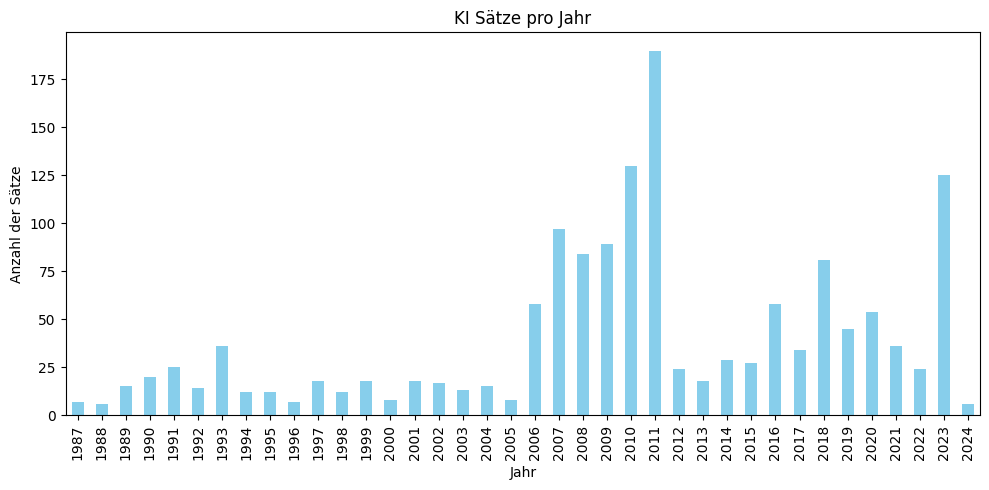

<Figure size 640x480 with 0 Axes>

In [62]:
# exclude unknown years ('0000') and aggregate counts
sents_years = pd.Series(sents_by_year['year'])
sents_years = sents_years[sents_years != '0000']
sents_by_year_count = sents_years.value_counts().sort_index()

# plot
plt.figure(figsize=(10,5))
sents_by_year_count.plot(kind='bar',color='skyblue')
plt.title('KI Sätze pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Sätze')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'KI_sentences_percent_per_year.png'))

In [63]:
# docs_leipzig is a dict loaded from JSON
# Extract IDs and map to years using metadata, conertd to df
rows = []
for d_id, sent in docs_leipzig.items():
    for i in docs_leipzig[d_id]:
    # Add one row per item
        rows.append({
            "id": docs_leipzig[d_id],
            "year": re.sub(r'\_\w+$', '', d_id) ,
            "text": docs_leipzig[d_id][i],
        })
leipzig_df = pd.DataFrame(rows)
leipzig_df.to_csv(sents_years_path, index=False)

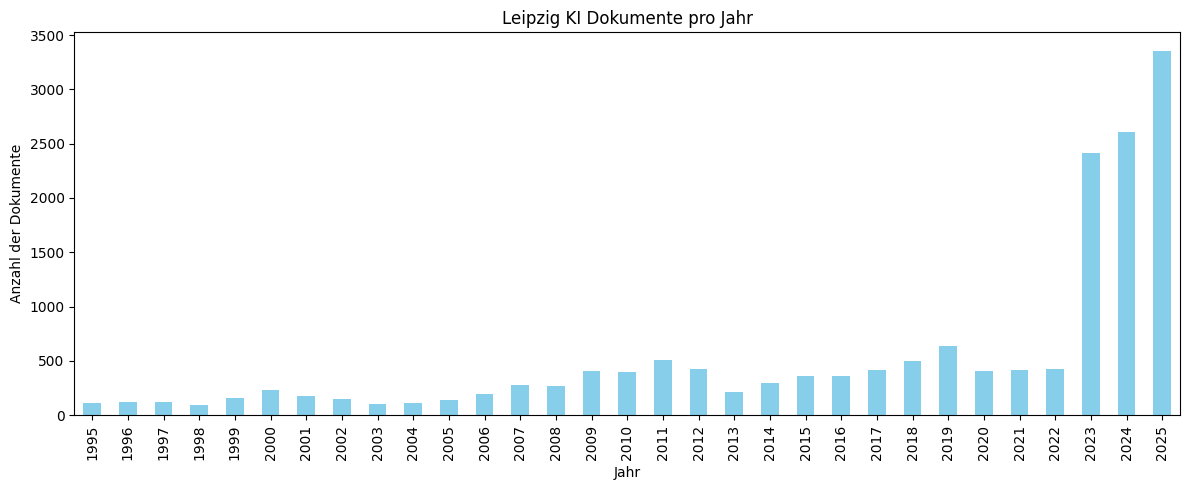

Total Leipzig docs with valid year: 16425
Year range: 1995 - 2025


<Figure size 640x480 with 0 Axes>

In [64]:
# Plot Leipzig docs with id mapped to year
# Count docs per year
leipzig_by_year = leipzig_df['year'].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 5))
leipzig_by_year.plot(kind='bar',color='skyblue')
plt.title('Leipzig KI Dokumente pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Dokumente')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'Leipzig_docs_per_year.png'))

print(f"Total Leipzig docs with valid year: {len(leipzig_df)}")
print(f"Year range: {leipzig_df['year'].min()} - {leipzig_df['year'].max()}")

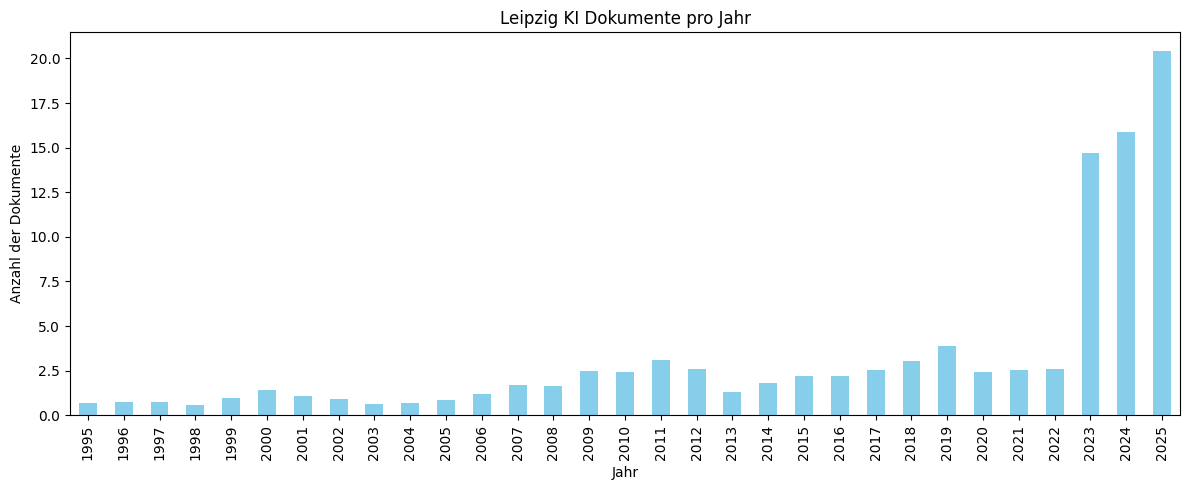

Total Leipzig docs with valid year: 16425
Year range: 1995 - 2025


<Figure size 640x480 with 0 Axes>

In [65]:
# percentage of Leipzig corpora KI sentences per year
# Plot Leipzig docs with id mapped to year in %
leipzig_by_year = leipzig_df['year'].value_counts().sort_index()
# calc percentaes
leipzig_by_year_percent = (leipzig_by_year / leipzig_by_year.sum()) * 100
leipzig_by_year_percent = leipzig_by_year_percent.round(2)
# save percentages
pd.DataFrame({'year': leipzig_by_year, 'percentage': leipzig_by_year_percent}).to_csv(sents_years_path,index= False)

# Plot
plt.figure(figsize=(12, 5))
leipzig_by_year_percent.plot(kind='bar', color='skyblue')
plt.title('Leipzig KI Dokumente pro Jahr')
plt.xlabel('Jahr')
plt.ylabel('Anzahl der Dokumente')
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(plots_dir, 'Leipzig_docs_percentage_year.png'))

print(f"Total Leipzig docs with valid year: {len(leipzig_df)}")
print(f"Year range: {leipzig_df['year'].min()} - {leipzig_df['year'].max()}")

In [66]:
# Häufigkeit der einzelnen KI Terme für beide datensätze
# convert leipzig_docs to dataframe as docs_sents with ids, sentences and years
all_sents_df = pd.concat([pd.read_csv(sents_years_path), pd.read_csv(sents_years_path)], ignore_index=True)
pprint(all_sents_df.head())

# average length of sentences
all_sents_df['sentence_length'] = all_sents_df['text'].apply(lambda x: len(x.split()))
avg_length = all_sents_df['sentence_length'].mean()
print("------------------------------------------------------------")
print(f"Average sentence length: {avg_length:.2f} words")


   year  percentage
0   116        0.71
1   124        0.75
2   118        0.72
3    95        0.58
4   159        0.97


KeyError: 'text'

In [ ]:
# number and type of verbs using tokens_from_item()
def count_POS(df_col, nlp, pos_tag): # Verb, ADJ, etc.
    tag_count = 0
    tag_types = Counter()
    for text in df_col:
        tokens = tokens_from_item(text, nlp)
        for token in tokens:
            if token.pos_ == pos_tag:
                tag_count += 1
                tag_types[token.lemma_] += 1
    print(f"Total {pos_tag}s: {tag_count}")
    print(f"{pos_tag} types:")
    for tag, count in tag_types.most_common():
        print(f"  {tag}: {count}")
    # plot top 20 types
    top_tags = tag_types.most_common(20)
    tags, counts = zip(*top_tags)
    plt.figure(figsize=(10,5))
    plt.bar(tags, counts)
    plt.title(f'Top {pos_tag} types')
    plt.xlabel(f'{pos_tag} lemma')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    plt.savefig(os.path.join(plots_dir, f'top_{pos_tag}_types.png')) 



In [ ]:
# count verbs in all sentences
count_POS(all_sents_df['text'], nlp, 'VERB')

In [ ]:
# count adjectives in all sentences
count_POS(all_sents_df['text'], nlp, 'ADJ')

In [ ]:
# Leipzig per-year plot: counts (bars) and percentage (line)
# Recompute year lists to be robust if earlier cells weren't run in order

years = sorted(set(list(year_counts.keys()) + list(year_total_counts.keys())))
counts = [year_counts.get(y, 0) for y in years]
totals = [year_total_counts.get(y, 0) for y in years]
percentages = [100 * (c / t) if t > 0 else 0 for c, t in zip(counts, totals)]

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(years, counts, color='skyblue', edgecolor='black', label='Anzahl anthropomorpher Sätze')
ax1.set_xlabel('Jahr', fontsize=18)
ax1.set_ylabel('Anzahl anthropomorpher Sätze', color='skyblue', fontsize=18)
ax1.tick_params(axis='y', labelcolor='skyblue', labelsize=15)
ax1.set_xticks(years)
ax1.set_xticklabels([str(y) for y in years], rotation=45, size=15)

ax2 = ax1.twinx()
ax2.plot(years, percentages, color='darkorange', marker='o', linewidth=2, label='Prozentsatz (%)')
ax2.set_ylabel('Prozentsatz (%)', color='darkorange', fontsize=18)
ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=15)

fig.suptitle('Leipzig: Anthropomorphie pro Jahr — Anzahl und Prozentsatz', fontsize=18)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])

# combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
fig.legend(lines + lines2, labels + labels2, loc='upper left')
plt.show()

plots_dir = 'plots/'
os.makedirs(plots_dir, exist_ok=True)
outpath = os.path.join(plots_dir, 'leipzig_anthro_per_year_counts_pct.png')
fig.savefig(outpath, bbox_inches='tight')
print('Saved:', outpath)


NameError: name 'year_counts' is not defined